In [3]:
import sys
import os
import json
import random
import matplotlib.pyplot as plt
from IPython.display import clear_output
import pandas as pd
import geopandas as gpd


sys.path.append('../')
import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING


In [4]:
inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [14]:
config = {
    

    "data": {
        "annotation_file": "/home/jan/Documents/EPFL/project_2/data/labels/dataset_v4/labels_55k.csv",
        "image_folder": "/home/jan/Documents/EPFL/project_2/data/images/dataset_v4/55k/four_images",
        "forestloss_folder": "/home/jan/Documents/EPFL/project_2/data/forestloss_tiles/dataset_v4",
        "output_folder":  "models_trained/"
    },

    "hyperparams" :{
        "seed": 424,
        "batch_size": 64,
        "learning_rate": [0.0005],
        "epochs": [20],
        "weight_decay": [0.002],
        "randomize_labels": ["False"],
        "model_type": "multitemporal",
        "backbone": "resnet18",
        "pretrained_backbone" : True,
        "in_channels": 4,
        "early_stopping_patience": [50],

        "use_forestloss" : True,
        "forestloss_params": 
            {
                "kernel_size" : 11,
                "sigma" : 5,
                "apply_after_layer" : 1
            },
        
            "folds_to_split" : 
            {
                0 : "train",
                1 : "train",
                2 : "val",
                3 : "train",
                4 : "test"
            }
        
        
        
    },


    "wandb": {
        "log_to_wandb" : "True",
        "project" : "project_2",
        "entity" : "janpisl",
        "group": "tmf March 2024 v2"
    }
}

In [15]:
# fetch dataloaders
dataloaders = dataloader.fetch_dataloader(
    ['train', 'val'], config)
train_dl = dataloaders['train']
val_dl = dataloaders['val']

In [16]:
x,y = next(iter(train_dl))

In [17]:
def plot_images(data, tmf, label):
    
    n_images = data.shape[0]
    print(label)
    fig, ax = plt.subplots(1,n_images+1, figsize=(16, 16))
    idx = 0
    for idx in range(n_images):
        img = data[idx, :3, :, :].detach()
        img = img/0.25

        ax[idx].imshow(img.permute(1, 2, 0)[:,:,[2,1,0]].numpy()  )
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])

    ax[n_images].imshow(tmf.permute(1, 2, 0).numpy())
    ax[n_images].set_xticks([])
    ax[n_images].set_yticks([])
    
    fig.tight_layout()
    plt.show()
    



Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


10577609 mapbiomas.csv
soy


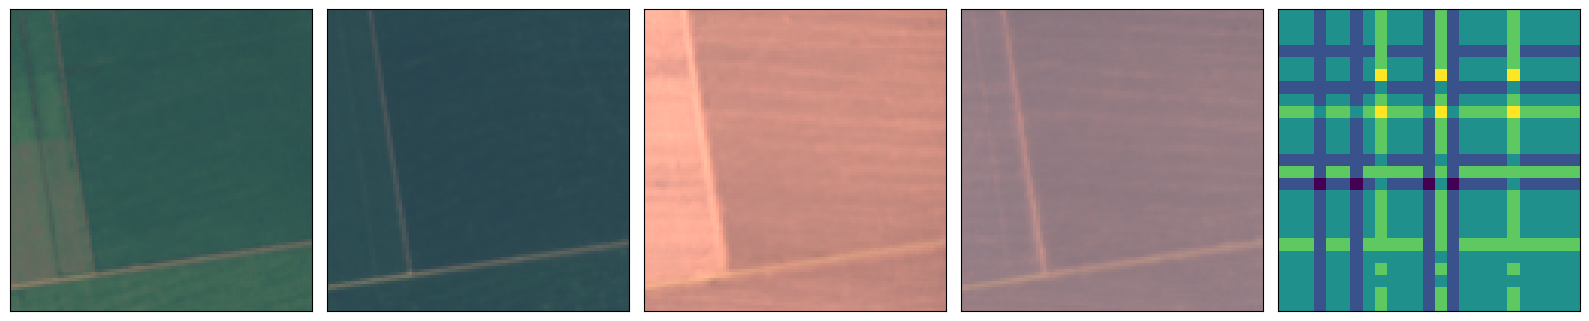

KeyboardInterrupt: 

In [23]:
dataset = train_dl.dataset

#for i in range(len(dataset)):
while True:
    i = random.randint(0,len(dataset.img_labels))
    #if not train_dataset.img_labels.iloc[i].driver == 'shifting agriculture':
    #    continue
    print(dataset.img_labels.iloc[i].sampleid, dataset.img_labels.iloc[i].dataset)
    input_batch, label = train_dl.dataset.__getitem__(i)
    ts, tmf = input_batch

    plot_images(ts,tmf, label= inverse_label_mapping[label])

    _waitforinput = input()

    clear_output(wait=True)

    
    
    
    

In [27]:
forestloss_dir = "/home/jan/Documents/EPFL/project_2/data/forestloss_tiles/dataset_v4"

In [28]:
with rasterio.open(os.path.join(forestloss_dir, f"{str(10577609)}.tif")) as src:
    tile = src.read()

In [30]:
tile.min()

1.0

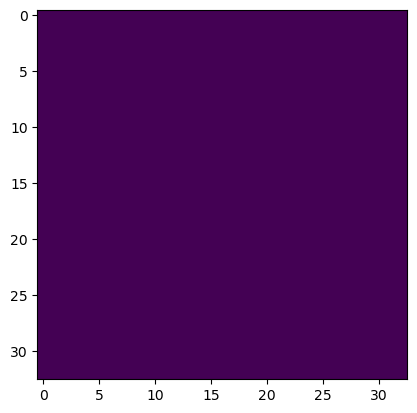

In [32]:
plt.imshow(tile.squeeze())

In [ ]:
sampleids = [
2040330, #forest plant. looks like palm oil
    5000927, #forest plant. looks like palm oil
    8118421,  #forest plant. looks like palm oil
]

In [21]:
train_dataset.img_labels.loc[train_dataset.img_labels.sampleid == 5002879]

,geometry,driver,sampleid,split
7438,POINT (105.97349049958846 14.335897554805385),shifting agriculture,5002879,train
